In [37]:
%load_ext autoreload
%autoreload 2
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import xr_ccew as tw
from src.wave_profiles import BOX_PROFILES as profiles

from src.wheeler_kiladis import (
    add_matsuno_curves,
    spectral_power_pipeline
)

from src.noaa_olr import (
    load_noaa_olr
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
olr = load_noaa_olr(
    lat_range=(-20, 20),
    time_range=("1990-01-01", "2010-12-31")
)

In [12]:
power_sym = spectral_power_pipeline(olr, which='symmetric')
power_asym = spectral_power_pipeline(olr, which='antisymmetric')
bg = tw.background_spectrum((power_sym+power_asym)/2)

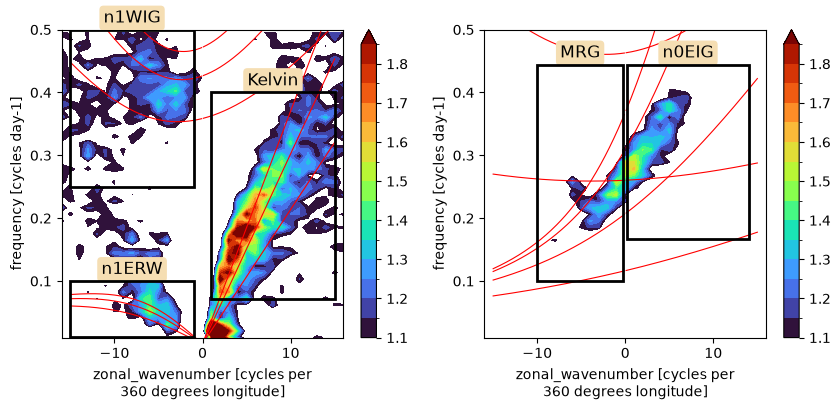

In [53]:
def wk99_plot(ax, power):
    levels = np.arange(1.1, 1.9, 0.05)
    power.plot.contourf(
        ax=ax,
        y='frequency',
        cmap=plt.cm.turbo,
        vmin=min(levels),
        vmax=max(levels),
        levels=len(levels),
        extend='max',
        cbar_kwargs={'label': None}
    )


fig, axs = plt.subplots(ncols=2, figsize=(10, 4))

ax = axs[0]
wk99_plot(ax, power_sym/bg)
add_matsuno_curves(ax, 'symmetric', he_list=[10, 20, 30])

ax = axs[1]
wk99_plot(ax, power_asym/bg)
add_matsuno_curves(ax, 'antisymmetric', he_list=[1, 10, 50, 100])


for wave, profile in profiles.items():
    ax = axs[0 if profile.symmetry == "symmetric" else 1]

    ax.add_patch(
        Rectangle(
            (profile.k_min, profile.frequency_min),
            profile.k_max - profile.k_min,
            profile.frequency_max - profile.frequency_min,
            fill=False,
            edgecolor="black",
            linewidth=2,
            zorder=5,
        )
    )
    ax.text(
        (profile.k_min + profile.k_max) / 2,
        profile.frequency_max + 0.005,
        wave,
        ha="center",
        va="bottom",
        fontsize=12,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="wheat",
            edgecolor="none",
        ),

    )

for ax in axs:     
    ax.set_ylim(0.01, 0.5)
    ax.set_xlim(-16, 16)


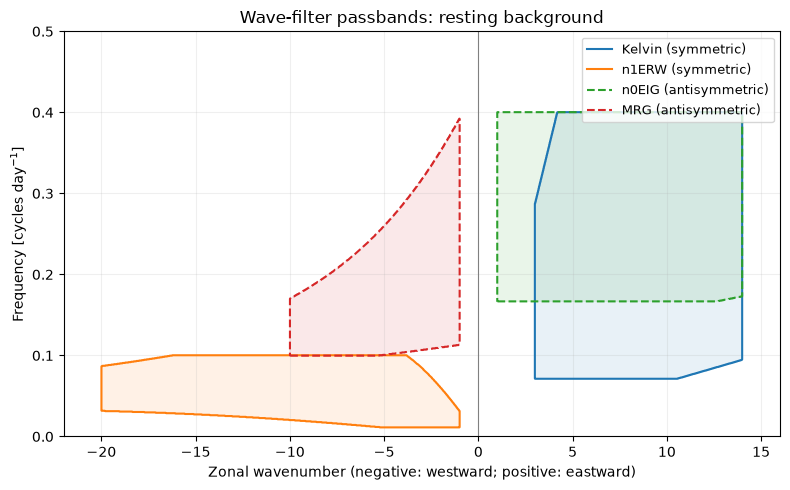

In [ ]:
# Dense plotting grid in WK coordinates; daily Nyquist is 0.5 cycles/day.
k = np.linspace(
    min(p.k_min for p in profiles.values()) - 2,
    max(p.k_max for p in profiles.values()) + 2,
    1601,
)
frequency = np.linspace(0, 0.5, 1001)

grid = xr.DataArray(
    np.zeros((frequency.size, k.size)),
    dims=("frequency", "zonal_wavenumber"),
    coords={"frequency": frequency, "zonal_wavenumber": k},
)

fig, ax = plt.subplots(figsize=(8, 5))
handles = []

for i, (wave, profile) in enumerate(profiles.items()):
    color = f"C{i}"
    linestyle = "-" if profile.symmetry == "symmetric" else "--"

    # Positive-frequency passband only; omit its negative-frequency partner.
    mask = tw.make_filter_mask(
        grid, profile,
        include_conjugates=False,
        background_u=0.0,
    ).transpose("frequency", "zonal_wavenumber")

    ax.contourf(
        k, frequency, mask.values.astype(float),
        levels=[0.5, 1.5], colors=[color], alpha=0.10,
    )
    ax.contour(
        k, frequency, mask.values.astype(float),
        levels=[0.5], colors=[color],
        linestyles=[linestyle], linewidths=1.5,
    )
    handles.append(Line2D(
        [], [], color=color, linestyle=linestyle,
        label=f"{wave} ({profile.symmetry})",
    ))

ax.axvline(0, color="0.5", linewidth=0.8)
ax.set(
    xlim=(k.min(), k.max()),
    ylim=(0, 0.5),
    xlabel="Zonal wavenumber (negative: westward; positive: eastward)",
    ylabel="Frequency [cycles day$^{-1}$]",
    title="Wave-filter passbands: resting background",
)
ax.legend(handles=handles, fontsize=9)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Profile passbands and Matsuno curves by symmetry

The panels separate the symmetric Kelvin/n=1 ER profiles from the antisymmetric
MRG/n=0 EIG profiles in `profiles`. Shaded regions and solid outlines are the
actual filter passbands. Colored theory curves show equivalent depths of **1,
10, 100 and 200 m**, distinguished by line style, for those wave families.
Curves assume a resting background and extend outside the filter passbands;
only positive frequencies up to the daily Nyquist limit are displayed.


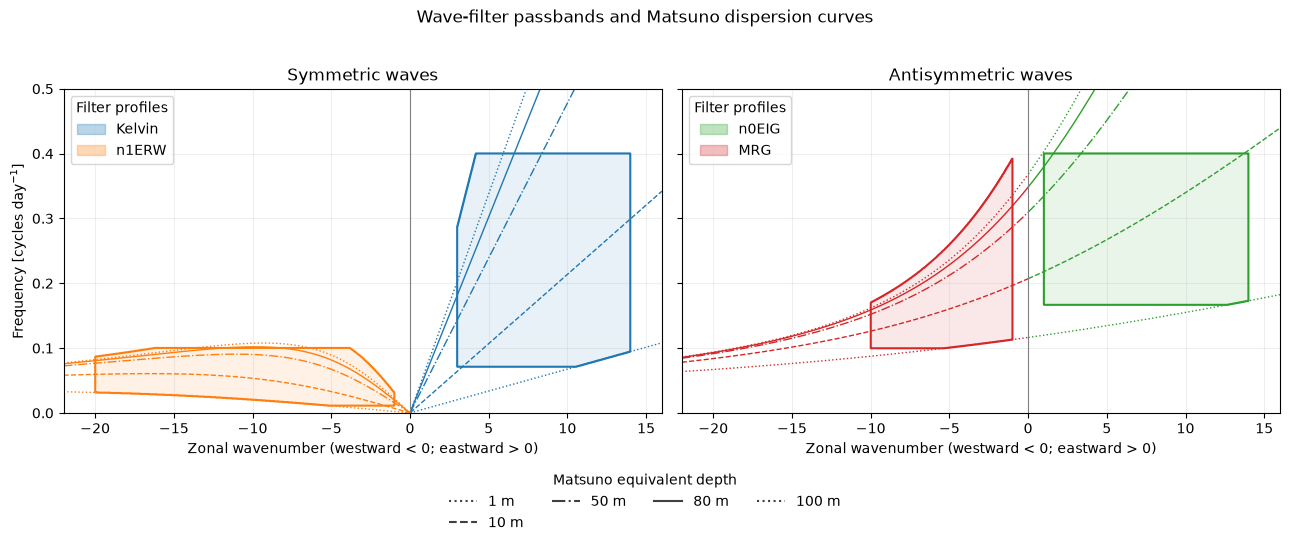

In [5]:
from matplotlib.patches import Patch
from xr_ccew.matsuno import profile_curve_frequency

# Plot the same profiles as above; the theoretical curves assume resting flow.
equivalent_depths_m = (1, 10, 50, 80, 100)
depth_linestyles = {1: ":", 10: "--", 50: "-.", 80: "-", 100: ":"}
profile_colors = {wave: f"C{i}" for i, wave in enumerate(profiles)}

# A plotting grid, rather than a data spectrum: no OLR loading is needed.
profile_k = np.linspace(
    min(p.k_min for p in profiles.values()) - 2,
    max(p.k_max for p in profiles.values()) + 2,
    1601,
)
profile_frequency = np.linspace(0, 0.5, 1001)  # Daily Nyquist [cycles/day].
profile_grid = xr.DataArray(
    np.zeros((profile_frequency.size, profile_k.size)),
    dims=("frequency", "zonal_wavenumber"),
    coords={"frequency": profile_frequency, "zonal_wavenumber": profile_k},
)

fig_profiles, axes_profiles = plt.subplots(
    1, 2, figsize=(13, 5.5), sharex=True, sharey=True,
)

for ax_profile, symmetry in zip(axes_profiles, ("symmetric", "antisymmetric")):
    wave_handles = []
    for wave, profile in profiles.items():
        if profile.symmetry != symmetry:
            continue
        color = profile_colors[wave]
        mask = tw.make_filter_mask(
            profile_grid, profile, include_conjugates=False, background_u=0.0,
        ).transpose("frequency", "zonal_wavenumber")
        ax_profile.contourf(
            profile_k, profile_frequency, mask.values.astype(float),
            levels=[0.5, 1.5], colors=[color], alpha=0.10,
        )
        ax_profile.contour(
            profile_k, profile_frequency, mask.values.astype(float),
            levels=[0.5], colors=[color], linewidths=1.5,
        )
        wave_handles.append(Patch(
            facecolor=color, edgecolor=color, alpha=0.3, label=wave,
        ))

        # Show each wave family's theory curves across the full plot domain,
        # including portions outside its frequency/wavenumber filter bounds.
        for depth in equivalent_depths_m:
            curve_frequency = profile_curve_frequency(
                profile.curve_name, profile_k, depth,
                meridional_mode_number=profile.meridional_mode_number,
                background_u=0.0,
            )
            ax_profile.plot(
                profile_k, curve_frequency, color=color,
                linestyle=depth_linestyles[depth], linewidth=1.0,
            )

    ax_profile.axvline(0, color="0.5", linewidth=0.8)
    ax_profile.set(
        xlim=(profile_k.min(), profile_k.max()), ylim=(0, 0.5),
        xlabel="Zonal wavenumber (westward < 0; eastward > 0)",
        title=f"{symmetry.capitalize()} waves",
    )
    ax_profile.legend(handles=wave_handles, loc="upper left", title="Filter profiles")
    ax_profile.grid(alpha=0.2)

axes_profiles[0].set_ylabel("Frequency [cycles day$^{-1}$]")
fig_profiles.suptitle("Wave-filter passbands and Matsuno dispersion curves")
fig_profiles.legend(
    handles=[Line2D([], [], color="0.25", linestyle=depth_linestyles[depth],
                    label=f"{depth} m") for depth in equivalent_depths_m],
    title="Matsuno equivalent depth", loc="lower center", ncol=4, frameon=False,
    bbox_to_anchor=(0.5, 0.01),
)
fig_profiles.tight_layout(rect=(0, 0.14, 1, 0.96))
plt.show()
